# Import Data

In [5]:
%time
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py 

# Import data
root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/"
filename = 'extracted_corrected_threshold_qn_matrixs_LW20230126.h5'
with h5py.File(root + filename, 'r') as f:
    qn_matrix = f['data/qn_matrix'][:]
    gene_names = f['meta/genes/all_gene_names'][:]
    biosample_names = f['meta/biosamples/threshold_biosample_names'][:]

biosample_names = [x.decode('UTF-8') for x in biosample_names]
gene_names = [x.decode('UTF-8') for x in gene_names]

# Variables 
category_dict  = {
    "Cardiovascular System" : ["Heart", "Atrium", "Cardiac Muscle Fiber", 
                               "Pericardium", "Valve", "Ventricle",
                               "HUVEC"], 
    
    "Connective Tissue" : ["Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
                           "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF"],

    "Digestive System": ["HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
                         "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
                         "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
                         "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus"],
    
    "Immune System" : ["Granulocyte", "Neutrophil", "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", 
                       "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
                       "Dendritic", "Kupffer", "Macrophage", "Macroglia", "JEG3", "Thymus", "Thymocyte", "Spleen"],
    
    "Integumentary System" : ["Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
                              "A431", "HACAT", "HNSCC"], 
    
    "Muscular System" : ["Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
                         "Vascular Smooth Muscle", "LHCNM2"], 
    
    "Nervous System" : ["Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
                        "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
                        "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron"], 
    
    "Respiratory System" : ["Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
                            "Trachea"], 
    
    "Urogenital System" : ["Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
                           "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
                           "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"], 
    
    "Other" : ["GSE30017"]
}

CPU times: user 0 ns, sys: 2 µs, total: 2 µs
Wall time: 7.63 µs


---
# Get Geneset 

In [191]:
def get_gene_names(filename, geneset_name):
    gene_names = []
    with open(filename) as file:
        for line in file:
            line = line.strip().split('\t')
            if line[0] == geneset_name:
                gene_names = line[2:]
                break
    return gene_names

# Input file name
root = "/home/lwu/ARCHS4/Tests/Check If Biosample Categorys Align With Genesets/"
filename = 'h.c1.c2.all.v7.5.1.symbols.gmt'

# Geneset name
geneset_name1 = "HALLMARK_INFLAMMATORY_RESPONSE"
geneset_name2 = "BRUNEAU_HEART_GREAT_VESSELS_AND_VALVULOGENESIS"
geneset_name3 = 'HALLMARK_TGF_BETA_SIGNALING'

# Call the function to get the gene names
gene_names1 = get_gene_names(root + filename, geneset_name1)
gene_names2 = get_gene_names(root + filename, geneset_name2)
gene_names3 = get_gene_names(root + filename, geneset_name3)

# Print the gene names
print(geneset_name1, len(gene_names1))
print(geneset_name2, len(gene_names2))
print(geneset_name3, len(gene_names3))

HALLMARK_INFLAMMATORY_RESPONSE 200
BRUNEAU_HEART_GREAT_VESSELS_AND_VALVULOGENESIS 8
HALLMARK_TGF_BETA_SIGNALING 54


In [194]:
def get_gene_indexes(gene_names, genes_names_all):
    gene_indexes = []
    for gene in gene_names:
        try:
            index = genes_names_all.index(gene)
            gene_indexes.append(index)
        except ValueError:
            print("Not Found: ", gene)
            gene_names.remove(gene)
    print()
    return gene_names, gene_indexes

# Call the function to get the gene indexes
gene_names1, gene_indexes1 = get_gene_indexes(gene_names1, gene_names)
gene_names2, gene_indexes2 = get_gene_indexes(gene_names2, gene_names)
gene_names3, gene_indexes3 = get_gene_indexes(gene_names3, gene_names)

# Print the gene indexes
print(len(gene_indexes1))
print(len(gene_indexes2))
print(len(gene_indexes3))
print()

print(geneset_name1, len(gene_names1))
print(geneset_name2, len(gene_names2))
print(geneset_name3, len(gene_names3))




196
8
52

HALLMARK_INFLAMMATORY_RESPONSE 196
BRUNEAU_HEART_GREAT_VESSELS_AND_VALVULOGENESIS 8
HALLMARK_TGF_BETA_SIGNALING 52


In [195]:
# CHANGABLE DATA
geneset_name_plot_title = geneset_name2
gene_indexes_plot = gene_indexes2
gene_names_plot = gene_names2

extracted_matrix = qn_matrix[gene_indexes_plot, :] 
print("Extracted Matrix Shape:", extracted_matrix.shape)

Extracted Matrix Shape: (8, 87875)


---
# Get System Averages 

In [196]:
result_dict = {}
for category, subcategories in category_dict.items():
    subcategory_dict = {}
    for subcategory in subcategories:
        subcategory_indices = [i for i, sample in enumerate(biosample_names) if 
                               subcategory.replace(" ", "").lower() in sample.lower()]
        if subcategory_indices:
            submatrix = extracted_matrix[:,subcategory_indices]
            subcategory_avg = np.mean(submatrix, axis=1)
            subcategory_dict[subcategory] = subcategory_avg.tolist()
    if subcategory_dict:
        result_dict[category] = subcategory_dict

In [197]:
system_averages = {}

for system, values in result_dict.items():
    average = [sum(col)/len(col) for col in zip(*values.values())]
    system_averages[system] = average #[round(x, 1) for x in average]

system_matrix = np.array([system_averages[key] for key in system_averages.keys()])
system_matrix = system_matrix.T
# print(list(system_matrix.keys()))
#print(system_matrix)
print(system_matrix.shape)

(8, 9)


In [198]:
# calculate the sums of each column and sort them in descending order
sums = system_matrix.sum(axis=0)
sorted_cols = np.argsort(sums)[::-1]

# reorder the matrix columns based on the sorted order
my_matrix = system_matrix[:, sorted_cols]
reordered_list = [list(system_averages.keys())[i] for i in sorted_cols]

# create a DataFrame from the matrix
df = pd.DataFrame(my_matrix, columns=reordered_list)
#print(df)


---
# Heatmap

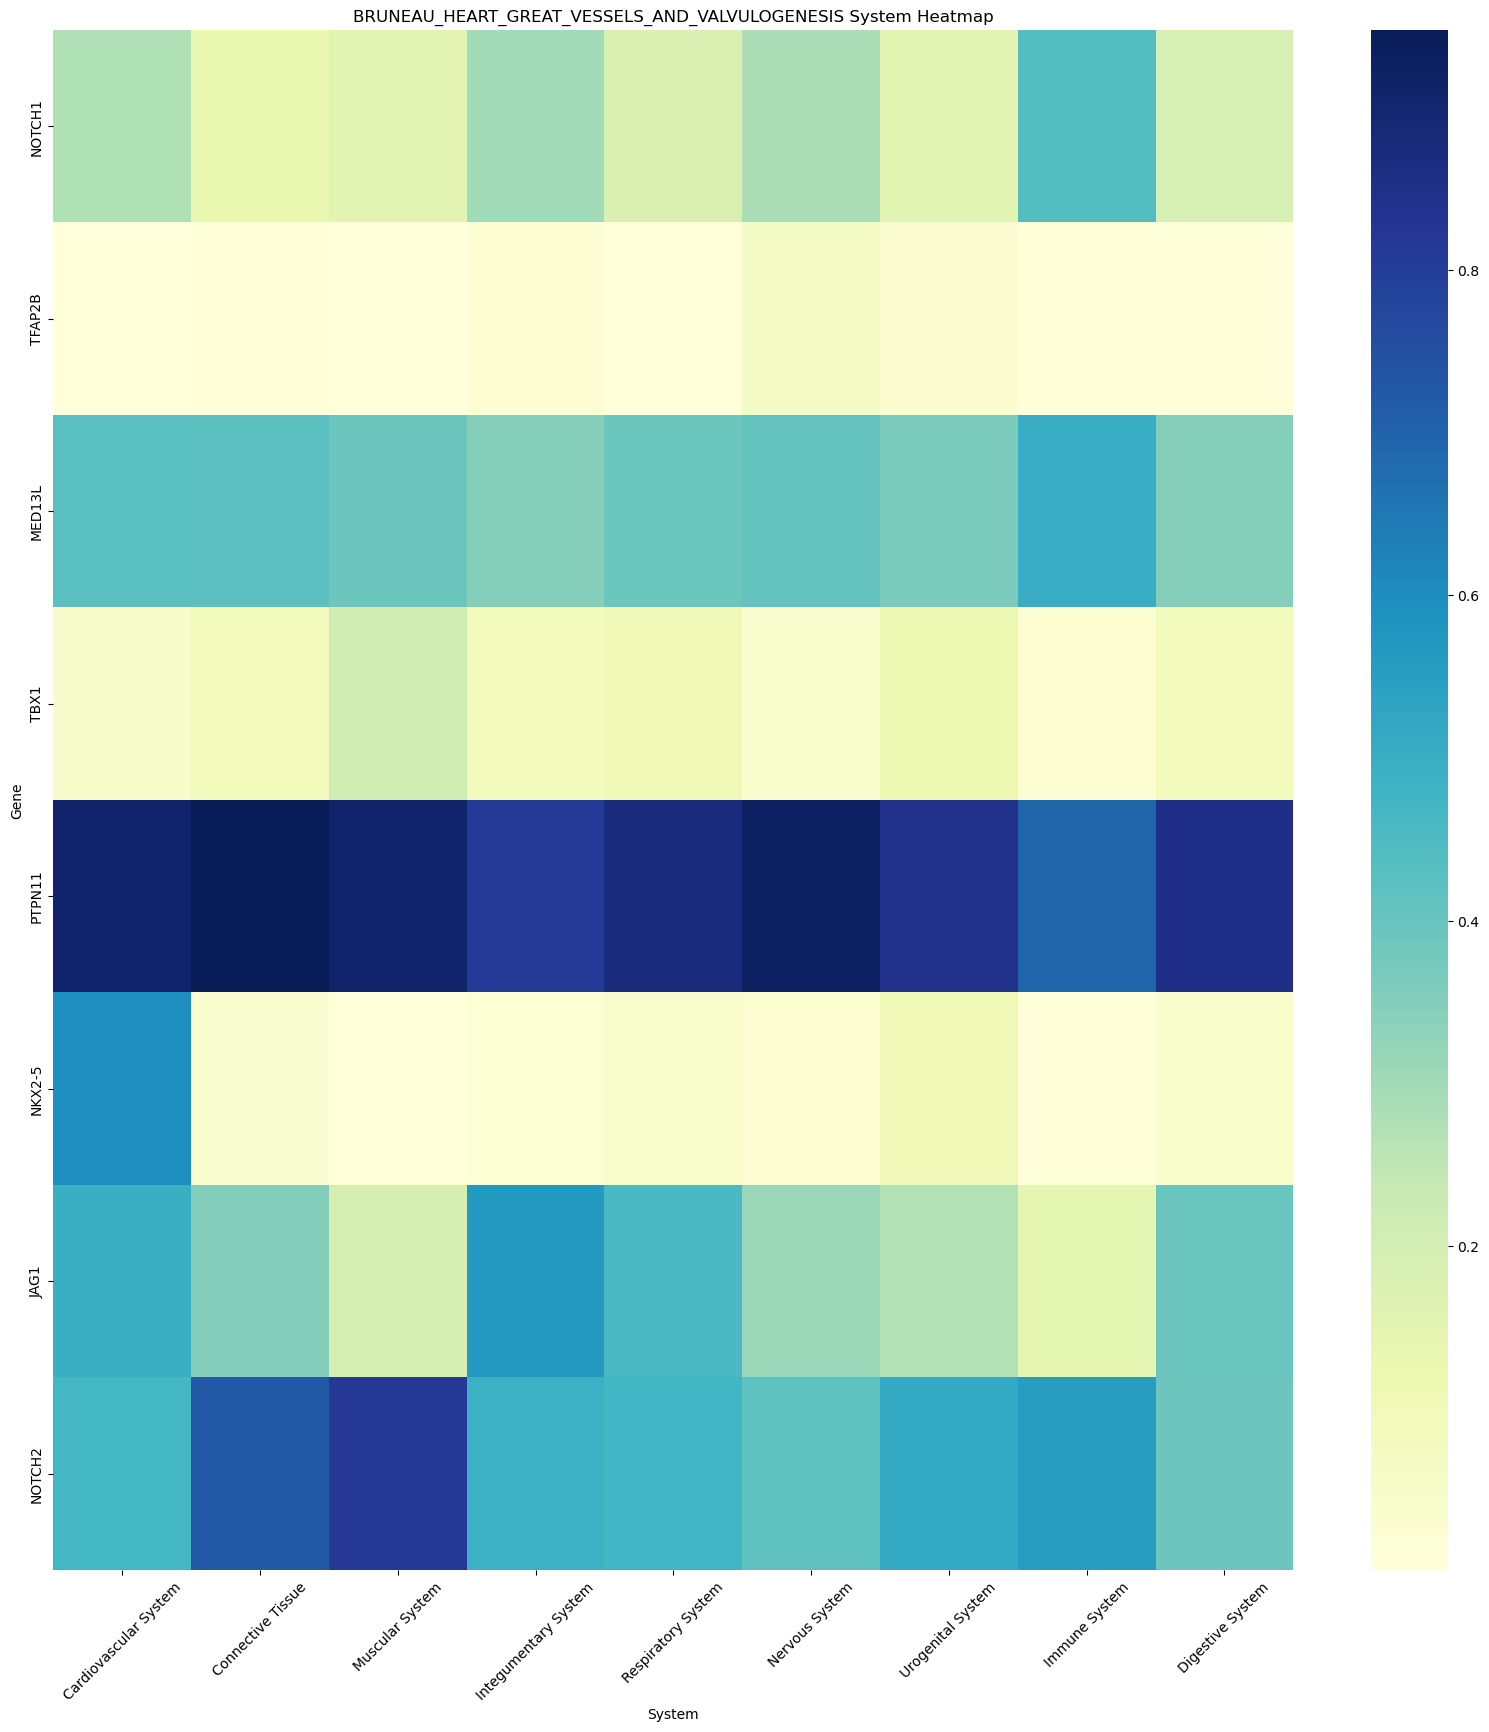

In [199]:

# Set the index of the dataframe to the row names
df.index = gene_names_plot

# create the heatmap using seaborn
plt.figure(figsize=(20, 20))
sns.heatmap(df, cmap='YlGnBu')
plt.xticks(rotation=45)
plt.title(geneset_name_plot_title + " System Heatmap")
plt.xlabel("System")
plt.ylabel("Gene")
plt.show()
